# PM2.5 Regression + Kriging (Combined SAT + Street-View)

Joint PCA across all satellite and street-view predictors.
Ridge regression in log-space + ordinary kriging of log-space residuals.
Predictions are clipped to [0, log1p(50)] before expm1 to prevent extreme extrapolation.

In [19]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'spatial' / 'grid_rectangles.geojson').exists() and (candidate / 'src').exists():
            return candidate
    raise FileNotFoundError('Could not find project root.')


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / 'data'

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

PROJECT_ROOT: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis


In [20]:
# ── Load all layers ───────────────────────────────────────────────────────
LAYER_DIR = DATA_DIR / 'kriging_satellite' / 'layers'
SV_DIR    = DATA_DIR / 'kriging_street_view'

sat_layer_paths = {
    'ndvi':         LAYER_DIR / 'ndvi_grid.geojson',
    'ndbi':         LAYER_DIR / 'ndbi_grid.geojson',
    'impervious':   LAYER_DIR / 'nlcd_impervious_grid.geojson',
    'road_density': LAYER_DIR / 'road_density_grid.geojson',
}
sv_layer_paths = {
    'gvi':        SV_DIR / 'grid_aggregated_gvi.geojson',
    'facades':    SV_DIR / 'grid_aggregated_facade_area.geojson',
    'cars':       SV_DIR / 'grid_aggregated_n_cars.geojson',
    'sky_ratio':  SV_DIR / 'grid_aggregated_sky_ratio.geojson',
    'road_ratio': SV_DIR / 'grid_aggregated_road_ratio.geojson',
}

missing = [k for k, p in {**sat_layer_paths, **sv_layer_paths}.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f'Missing layers: {missing}')

sat_gdfs = {name: gpd.read_file(path) for name, path in sat_layer_paths.items()}
sv_gdfs  = {name: gpd.read_file(path) for name, path in sv_layer_paths.items()}
print('SAT layers:', list(sat_gdfs))
print('SV  layers:', list(sv_gdfs))

SAT layers: ['ndvi', 'ndbi', 'impervious', 'road_density']
SV  layers: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


In [21]:
# ── Load sensor PM2.5 ─────────────────────────────────────────────────────
SENSORS_DIR = DATA_DIR / 'sensors'
sensor_csvs = {
    'Boston Carter Field':               SENSORS_DIR / 'boston_carter_field'         / 'boston_carter_field.csv',
    'Boston Gainsborough Parking Garage': SENSORS_DIR / 'boston_gainsborough_parking' / 'boston_gainsborough_parking.csv',
    'Boston Robinson Hall':              SENSORS_DIR / 'boston_robinson_hall'         / 'boston_robinson_hall.csv',
    'Boston West Village B':             SENSORS_DIR / 'boston_west_village_b'        / 'boston_west_village_b.csv',
    'Boston World Series Way':           SENSORS_DIR / 'boston_world_series_way'      / 'boston_world_series_way.csv',
}

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}
aligned_df, _ = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name='pm25',
    time_column='timestamp',
    sampling_interval='1min',
    timestamp_tolerance='15min',
)
sensor_pm25 = aligned_df.between_time('15:00', '16:00').mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / 'spatial' / 'sensor_locations.json')
sensor_names = list(sensor_csvs.keys())
sensor_locations = sensor_locations[sensor_locations['sensor_name'].isin(sensor_names)]
sensor_locations = sensor_locations.set_index('sensor_name').loc[sensor_names].reset_index()
sensor_locations['pm25'] = sensor_pm25.reindex(sensor_names).values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations['longitude'], sensor_locations['latitude']),
    crs='EPSG:4326',
)
print(f'Sensors loaded: {len(gdf_sensors)}')
gdf_sensors[['sensor_name', 'pm25', 'geometry']]

Sensors loaded: 5


,sensor_name,pm25,geometry
0,Boston Carter Field,10.322884,POINT (-71.08435 42.33925)
1,Boston Gainsborough Parking Garage,16.439812,POINT (-71.08508 42.34039)
2,Boston Robinson Hall,0.003135,POINT (-71.08652 42.33919)
3,Boston West Village B,0.884483,POINT (-71.09238 42.33765)
4,Boston World Series Way,23.751881,POINT (-71.0899 42.33874)


In [22]:
# ── Build combined grid ───────────────────────────────────────────────────
def _ensure_grid_id(gdf):
    if 'grid_id' in gdf.columns: return gdf.copy()
    if 'id'      in gdf.columns: return gdf.copy().rename(columns={'id': 'grid_id'})
    return gdf.reset_index(drop=False).rename(columns={'index': 'grid_id'})

def _pick_col(gdf, candidates):
    for c in candidates:
        if c in gdf.columns: return c
    raise ValueError(f'None of {candidates} in {list(gdf.columns)}')

sat_specs = [
    ('ndvi',         ['ndvi', 'ndvi_mean']),
    ('ndbi',         ['ndbi', 'ndbi_mean']),
    ('impervious',   ['impervious', 'nlcd_impervious']),
    ('road_density', ['road_density_km_km2', 'road_density']),
]
sv_specs = [
    ('gvi',        ['gvi_mean', 'gvi']),
    ('facades',    ['facade_area_mean', 'facade_area', 'facades']),
    ('cars',       ['n_cars_mean', 'n_cars', 'cars']),
    ('sky_ratio',  ['sky_ratio_mean', 'sky_ratio']),
    ('road_ratio', ['road_ratio_mean', 'road_ratio']),
]

base = _ensure_grid_id(sat_gdfs['ndvi'])
base_crs = base.crs
grid_features = base[['grid_id', 'geometry']].copy()

for out_name, candidates in sat_specs:
    layer = _ensure_grid_id(sat_gdfs[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

for out_name, candidates in sv_specs:
    layer = _ensure_grid_id(sv_gdfs[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

# road_density NaNs = 0 (no road), SV NaNs = median
grid_features['road_density'] = grid_features['road_density'].fillna(0.0)
print(f'Grid cells: {len(grid_features)}')
print(f'NaN counts:\n{grid_features.drop(columns=["grid_id","geometry"]).isna().sum()}')

Grid cells: 900
NaN counts:
ndvi             0
ndbi             0
impervious       0
road_density     0
gvi             43
facades         43
cars            43
sky_ratio       43
road_ratio      43
dtype: int64


In [23]:
# ── Joint PCA → combined_pc1, combined_pc2 ────────────────────────────────
target_col = 'pm25'

grid_features['road_density_log1p'] = np.log1p(grid_features['road_density'].clip(lower=0.0))
grid_features['cars_log1p']         = np.log1p(grid_features['cars'].clip(lower=0.0))

predictor_cols_pca = [
    'ndvi', 'ndbi', 'road_density_log1p', 'gvi', 'cars_log1p',
]

for col in predictor_cols_pca:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

scaler = StandardScaler()
pca    = PCA(n_components=2)
X_grid_scaled = scaler.fit_transform(grid_features[predictor_cols_pca])
X_grid_pca    = pca.fit_transform(X_grid_scaled)
grid_features['combined_pc1'] = X_grid_pca[:, 0]
grid_features['combined_pc2'] = X_grid_pca[:, 1]

print(f'Combined PCA — PC1: {pca.explained_variance_ratio_[0]:.3f}, PC2: {pca.explained_variance_ratio_[1]:.3f}, total: {pca.explained_variance_ratio_.sum():.3f}')
print('\nPCA loadings:')
for i, pc in enumerate(pca.components_):
    print(f'  PC{i+1}:', '  '.join(f'{feat}={val:+.3f}' for feat, val in zip(predictor_cols_pca, pc)))

# ── Map sensors → grid ────────────────────────────────────────────────────
sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(sensors_proj, grid_features, how='left', predicate='within')

unmatched = sensor_with_grid['grid_id'].isna()
if unmatched.any():
    nearest = gpd.sjoin_nearest(sensors_proj.loc[unmatched].copy(), grid_features, how='left', distance_col='_d')
    sensor_with_grid.loc[unmatched, ['grid_id'] + predictor_cols_pca] = nearest[['grid_id'] + predictor_cols_pca].to_numpy()

sensor_cell_df = pd.DataFrame({
    'sensor_name': sensor_with_grid['sensor_name'],
    target_col:    sensor_with_grid[target_col],
    'grid_id':     sensor_with_grid['grid_id'],
    **{c: sensor_with_grid[c] for c in predictor_cols_pca},
}).drop_duplicates(subset=['sensor_name']).reset_index(drop=True)


X_sensor_scaled = scaler.transform(sensor_cell_df[predictor_cols_pca].fillna(0))
X_sensor_pca    = pca.transform(X_sensor_scaled)
sensor_cell_df['combined_pc1'] = X_sensor_pca[:, 0]
sensor_cell_df['combined_pc2'] = X_sensor_pca[:, 1]

predictor_cols = ['combined_pc1', 'combined_pc2']
train_df = sensor_cell_df[[target_col] + predictor_cols].dropna().copy()
train_df['pm25_log1p'] = np.log1p(train_df[target_col].clip(lower=0.0))

ridge_model = train_ridge(
    X=train_df[predictor_cols].to_numpy(dtype=float),
    y=train_df['pm25_log1p'],
    alpha=10,
    fit_intercept=True,
)
print('\nRidge trained (pm25)')
print('n_samples:', ridge_model['n_samples'])
print('score_r2:', ridge_model['score_r2'])
for name, coef in zip(predictor_cols, ridge_model['coefficients']):
    print(f'  {name}: {coef:.6f}')
print('intercept:', ridge_model['intercept'])

Combined PCA — PC1: 0.467, PC2: 0.196, total: 0.662

PCA loadings:
  PC1: ndvi=-0.598  ndbi=+0.601  road_density_log1p=+0.298  gvi=-0.363  cars_log1p=+0.245
  PC2: ndvi=+0.176  ndbi=-0.154  road_density_log1p=+0.640  gvi=+0.397  cars_log1p=+0.615

Ridge trained (pm25)
n_samples: 5
score_r2: 0.35466206207410944
  combined_pc1: 0.323528
  combined_pc2: -0.050008
intercept: 1.8060615155765265


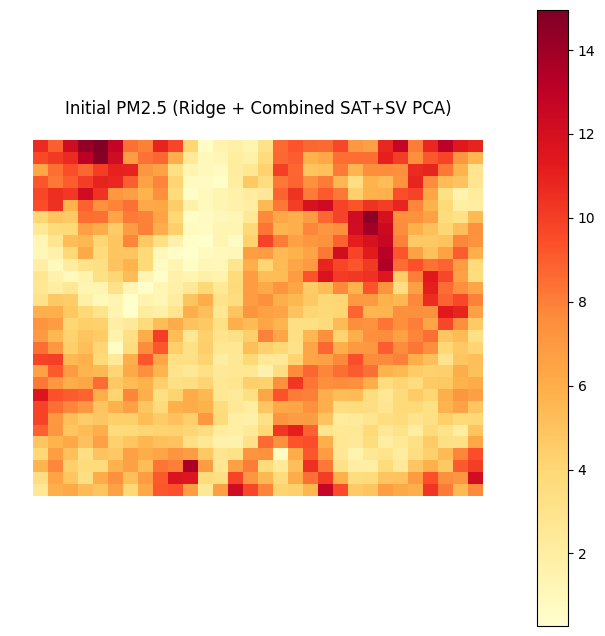

In [24]:
# ── Predict PM2.5 on full grid ────────────────────────────────────────────
X_grid = grid_features[predictor_cols].to_numpy(dtype=float)
grid_features['predicted_log_pm25_ridge'] = ridge_predict(ridge_model, X_grid).clip(0, np.log1p(50))
grid_features['predicted_pm25_ridge']     = np.expm1(grid_features['predicted_log_pm25_ridge']).clip(lower=0.0)

initial_pm25_map = gpd.GeoDataFrame(grid_features, geometry='geometry', crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
initial_pm25_map.plot(column='predicted_pm25_ridge', cmap='YlOrRd', legend=True, ax=ax)
ax.set_axis_off()
ax.set_title('Initial PM2.5 (Ridge + Combined SAT+SV PCA)')
plt.show()

In [25]:
# ── Sensor residuals in log-space ─────────────────────────────────────────
sensor_model_df = sensor_cell_df[['sensor_name', target_col] + predictor_cols].dropna().copy()
sensor_model_df['ridge_pred_log'] = ridge_predict(ridge_model, sensor_model_df[predictor_cols].to_numpy(dtype=float))
sensor_model_df['observed_log_pm25'] = np.log1p(sensor_model_df[target_col].clip(lower=0.0))
sensor_model_df['residual'] = sensor_model_df['observed_log_pm25'] - sensor_model_df['ridge_pred_log']

sensors_proj = gdf_sensors.to_crs(initial_pm25_map.crs).copy()
sensors_proj['x'] = sensors_proj.geometry.x
sensors_proj['y'] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[['sensor_name', 'x', 'y']], on='sensor_name', how='left'
)
sensor_residuals_df

,sensor_name,pm25,combined_pc1,combined_pc2,ridge_pred_log,observed_log_pm25,residual,x,y
0,Boston Carter Field,10.322884,0.085204,-1.232479,1.895261,2.426826,0.531565,234252.312622,898834.637669
1,Boston Gainsborough Parking Garage,16.439812,1.783983,-1.135195,2.439998,2.858756,0.418758,234191.453996,898960.969606
2,Boston Robinson Hall,0.003135,-0.636600,-0.362681,1.618241,0.003130,-1.615111,234073.213353,898826.532851
3,Boston West Village B,0.884483,-1.624819,-0.063202,1.283548,0.633653,-0.649895,233591.199929,898653.278770
4,Boston World Series Way,23.751881,0.272906,0.002730,1.894218,3.208901,1.314684,233795.319059,898775.220621


Residual variogram model:
{'model': 'gaussian', 'nugget': 0.0, 'sill': 1.716739297276736, 'range': 133.49931965358485, 'score_mse': 2.1888524530355875, 'lag_centers': [128.53819628807997, 214.23032714679997, 299.92245800551996, 471.30671972295994, 642.6909814403999], 'experimental_semivariance': [0.006362701377364032, 2.1007344702239443, 4.29184824319184, 0.3912667707631286, 0.63446643135517], 'fitted_semivariance': [1.0373968702578513, 1.586023627096166, 1.7057064901244765, 1.7167326634954876, 1.7167392971290585]}


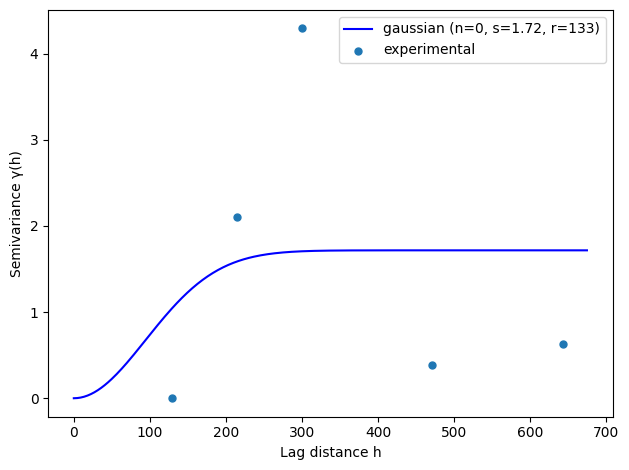

In [26]:
# ── Fit variogram ─────────────────────────────────────────────────────────
res_points = list(zip(sensor_residuals_df['x'].tolist(), sensor_residuals_df['y'].tolist()))
res_values = sensor_residuals_df['residual'].tolist()

residual_variogram_model = fit_variogram_model(points=res_points, values=res_values)
print('Residual variogram model:')
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

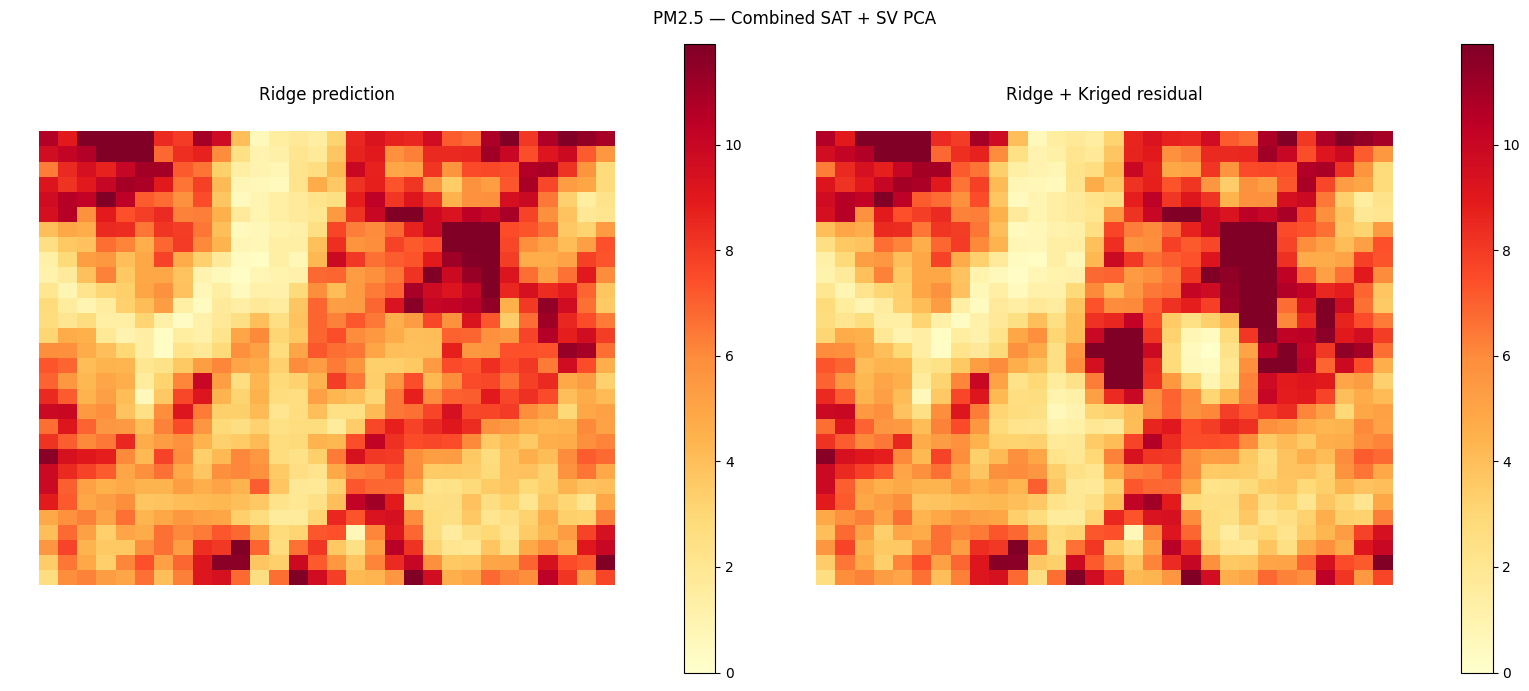

PM2.5 range: 0.00 – 23.12 µg/m³
Saved → /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_combined/pm25_combined_kriging_grid.geojson


In [27]:
# ── Krige log-space residuals → final PM2.5 map ───────────────────────────
query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_pm25_map.geometry]
estimated_residuals = ordinary_kriging_predict(
    points=res_points, values=res_values,
    fit=residual_variogram_model, query_points=query_points,
)

final_pm25_map = initial_pm25_map.copy()
final_pm25_map['estimated_residual_log'] = estimated_residuals
final_pm25_map['final_log_pm25'] = (
    final_pm25_map['predicted_log_pm25_ridge'] + final_pm25_map['estimated_residual_log']
).clip(0, np.log1p(50))
final_pm25_map['final_pm25'] = np.expm1(final_pm25_map['final_log_pm25']).clip(lower=0.0)

OUT_DIR = DATA_DIR / 'kriging_combined'
OUT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
vmax = float(final_pm25_map['final_pm25'].quantile(0.95))
initial_pm25_map.plot(column='predicted_pm25_ridge', cmap='YlOrRd', legend=True, vmin=0, vmax=vmax, ax=axes[0])
axes[0].set_axis_off(); axes[0].set_title('Ridge prediction')
final_pm25_map.plot(column='final_pm25', cmap='YlOrRd', legend=True, vmin=0, vmax=vmax, ax=axes[1])
axes[1].set_axis_off(); axes[1].set_title('Ridge + Kriged residual')
plt.suptitle('PM2.5 — Combined SAT + SV PCA')
plt.tight_layout()
plt.savefig(OUT_DIR / 'pm25_combined_map.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'PM2.5 range: {final_pm25_map["final_pm25"].min():.2f} – {final_pm25_map["final_pm25"].max():.2f} µg/m³')

OUTPUT_PATH = OUT_DIR / 'pm25_combined_kriging_grid.geojson'
final_pm25_map.to_file(OUTPUT_PATH, driver='GeoJSON')
print(f'Saved → {OUTPUT_PATH}')